# Ecommerce Return Classification

### Defining Business Problem:
> Business is getting too many returns and we have data of Orders from cart amount to return risk or return success

### Identifying Target Variable
> return_risk_label

#### Why:
> Need to minimize risk for returns on Orders.

### Basic Explaining Of Business pronlem
> An Ecommerce Business company  wants to predict which orders are likely to be returned, So it can be Identify high risk order and reduce Product Returns.

### How ML can address the problem?
> In this problem we can use Classification Models that can help us to identify either received order has high return risk or not.

# Data Understanding &amp; EDA

### Dataset structure and data types

In [62]:
import pandas as pd
import numpy as np

In [63]:
df = pd.read_csv("../raw_data/ecommerce_return_classification.csv")

In [64]:
df.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [65]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


### Descriptive statistics

In [66]:
df.describe()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,newsletter_subscriber,return_risk_label
count,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.630274,0.284024,0.354160,5.974273,23.879051,0.503508,0.645506
std,121.454170,0.159998,0.478338,3.188330,17.263143,0.500071,0.478440
min,0.000000,0.005000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,135.370000,0.157000,0.000000,3.000000,10.000000,0.000000,0.000000
50%,238.690000,0.265000,0.000000,6.000000,20.000000,1.000000,1.000000
75%,343.680000,0.386000,1.000000,9.000000,40.000000,1.000000,1.000000
max,449.860000,0.884000,1.000000,11.000000,50.000000,1.000000,1.000000


### Missing values and duplicates

In [67]:
df.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [68]:
df.duplicated().sum()

np.int64(0)

### Helping and Reuseable Code

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
all_num_cols = df.describe().columns
all_cat_cols = df.describe(include="O").columns

def showBoxPlot(data, col):
    plt.title(f"Box plot for Checking Outliers for: {col}")
    sns.boxplot(x=data[col])
    plt.xlabel(col)
    plt.show()

/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_18725/2311315400.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  all_cat_cols = df.describe(include="O").columns


### Outlier analysis

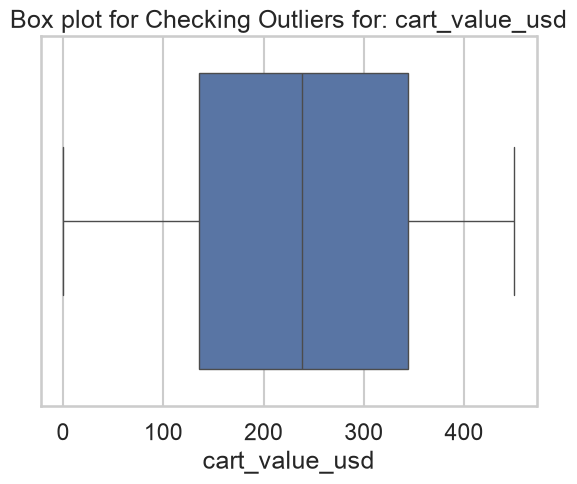

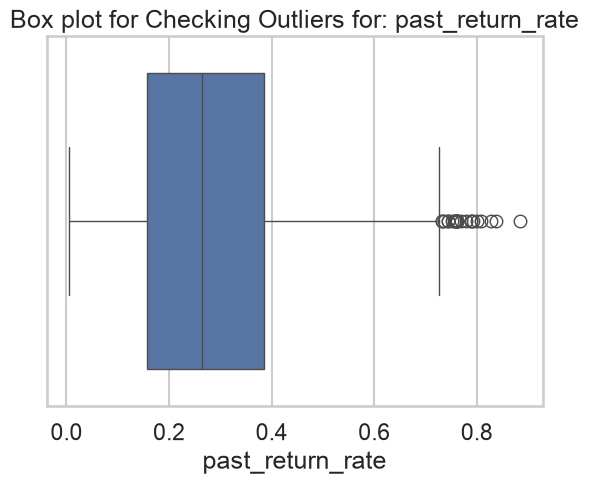

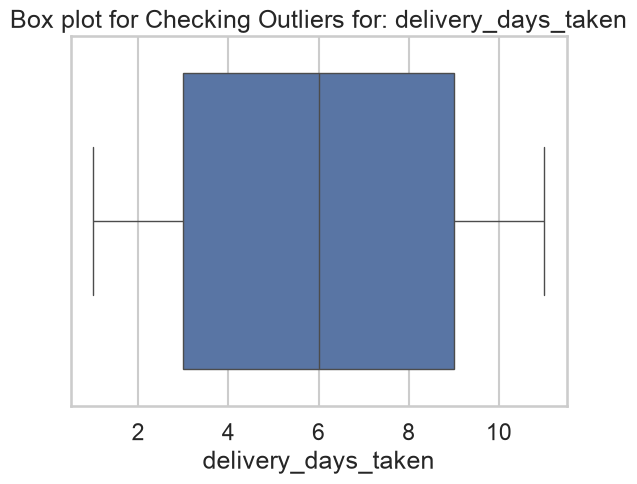

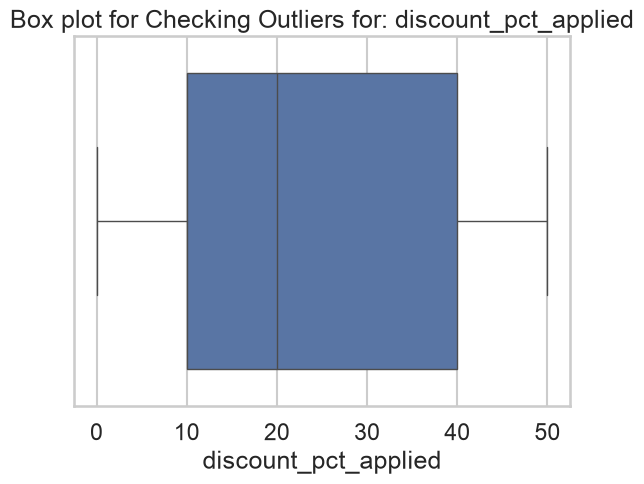

In [71]:
for col in all_num_cols.drop(["return_risk_label", "newsletter_subscriber", "size_bracketing_flag"]):
    showBoxPlot(df, col)

We Can Clearly see Outliers in Past Return Rate So need to remove Outlier in data

In [72]:
q1 = df["past_return_rate"].quantile(0.25)
q3 = df["past_return_rate"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)

lower_bound = lower_bound if lower_bound >= 0  else 0

print(lower_bound)

Lower Bound:  -0.18650000000000003
Upper Bound:  0.7295
0


In [73]:
df = df[(df["past_return_rate"] > lower_bound) & (df["past_return_rate"] < upper_bound)]

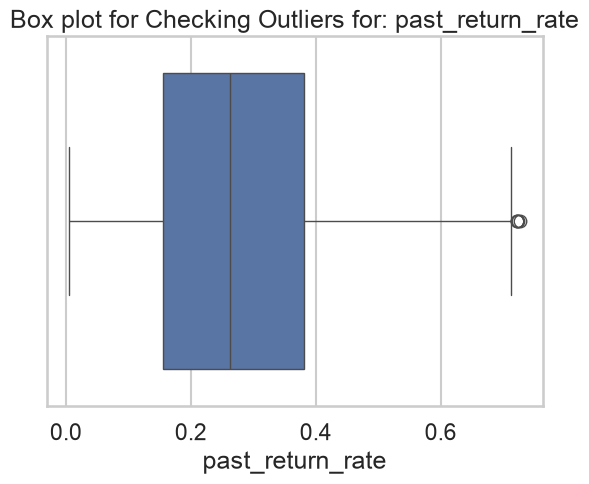

In [74]:
showBoxPlot(df, "past_return_rate")

### Relevant visualizations

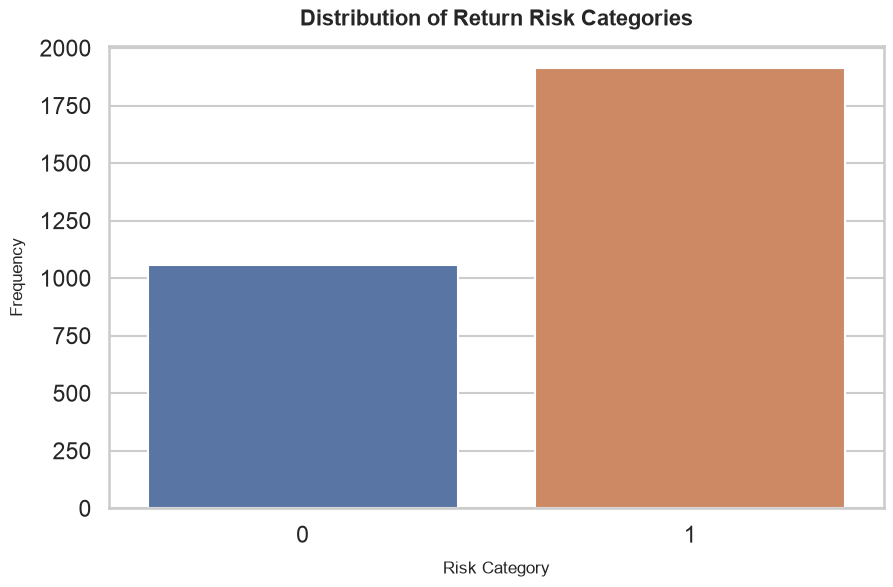

In [75]:
plt.figure(figsize=(10, 6))

counts = df["return_risk_label"].value_counts()

ax = sns.barplot(
    x=counts.index, 
    y=counts.values, 
    hue=counts.index, 
    legend=False
)

plt.title("Distribution of Return Risk Categories", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Risk Category", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Frequency", fontsize=12, fontweight="medium", labelpad=10)

plt.show()

In [76]:
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

<Axes: xlabel='cart_value_usd', ylabel='past_return_rate'>

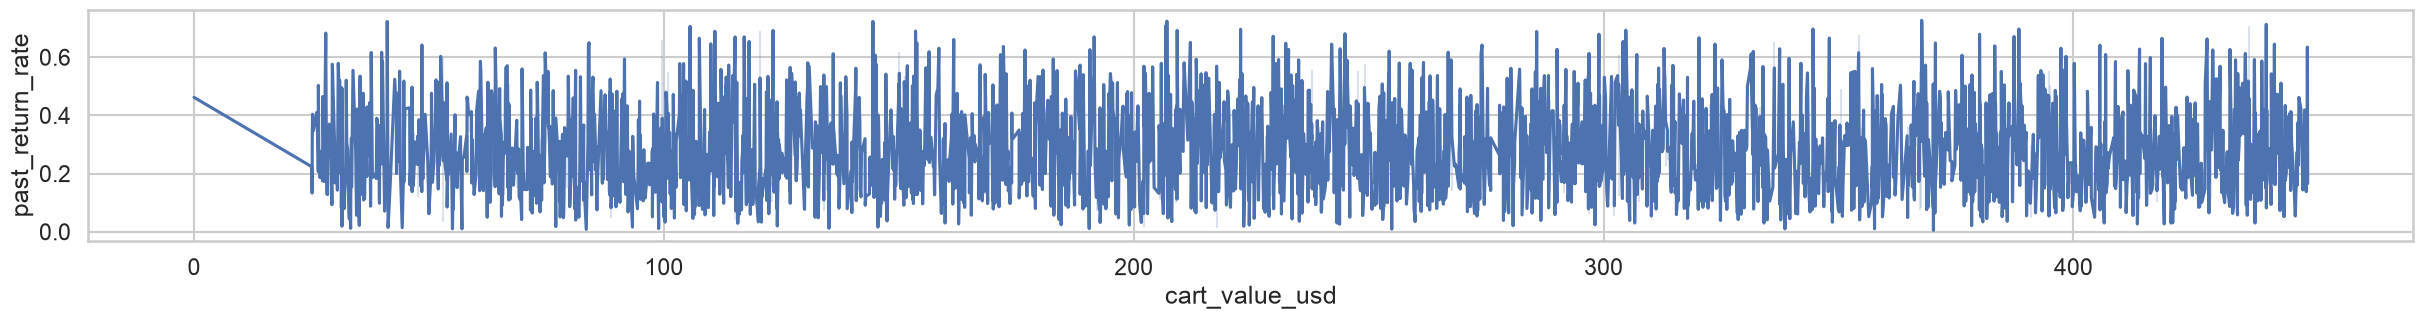

In [77]:
plt.figure(figsize=(30, 3))
sns.lineplot( x="cart_value_usd", y="past_return_rate", data=df)

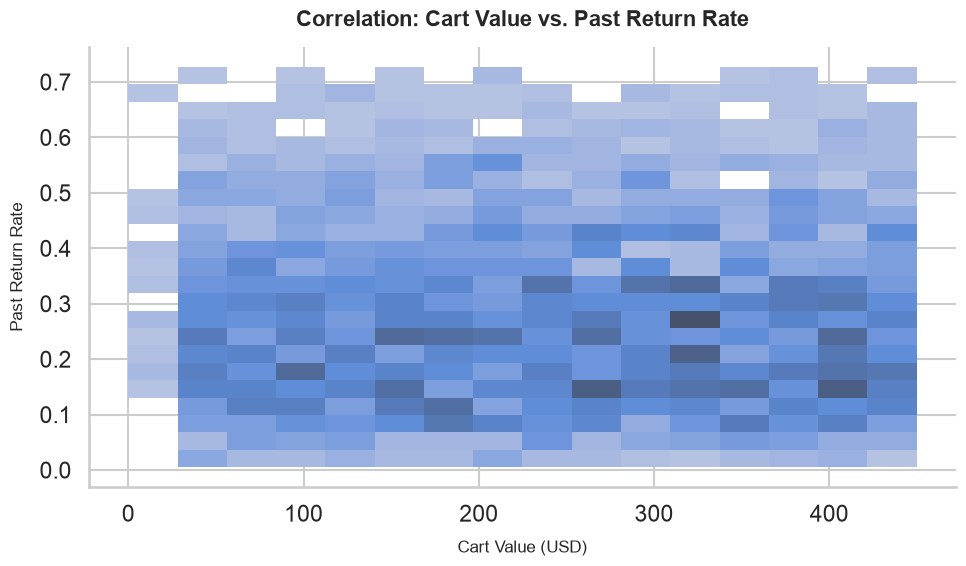

In [78]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", context="talk")

sns.histplot(
    x="cart_value_usd", 
    y="past_return_rate", 
    data=df,
)

plt.title("Correlation: Cart Value vs. Past Return Rate", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Cart Value (USD)", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Past Return Rate", fontsize=12, fontweight="medium", labelpad=10)

sns.despine()
plt.tight_layout()
plt.show()

<Axes: xlabel='delivery_days_taken', ylabel='past_return_rate'>

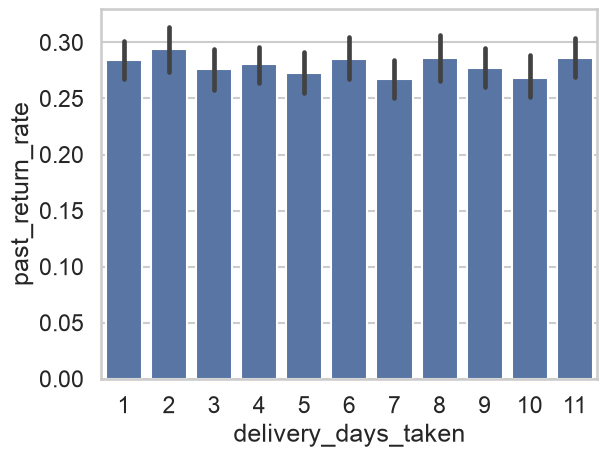

In [79]:
sns.barplot(
    data=df,
    x="delivery_days_taken",
    y="past_return_rate"
)

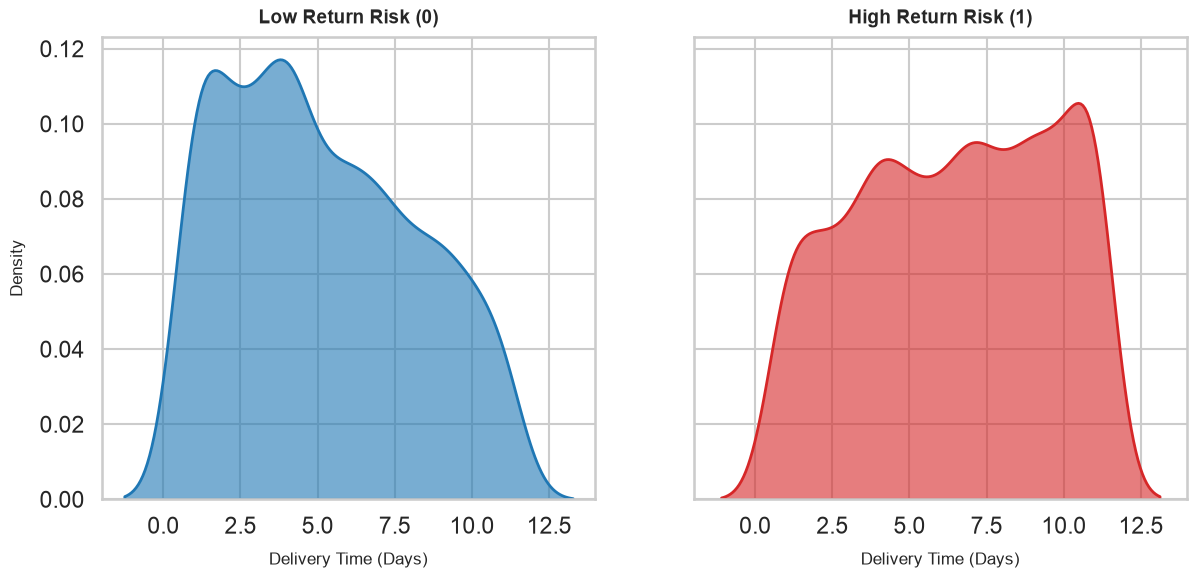

In [80]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), sharex=True, sharey=True)

sns.kdeplot(
    data=df[df["return_risk_label"] == 0],
    x="delivery_days_taken",
    fill=True,
    alpha=0.6,
    color="#1f77b4", # Blue implies normal/safe
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title("Low Return Risk (0)", fontsize=14, fontweight="bold", pad=10)
axes[0].set_xlabel("Delivery Time (Days)", fontsize=12, fontweight="medium", labelpad=10)
axes[0].set_ylabel("Density", fontsize=12, fontweight="medium", labelpad=10)

sns.kdeplot(
    data=df[df["return_risk_label"] == 1],
    x="delivery_days_taken",
    fill=True,
    alpha=0.6,
    color="#d62728", # Red implies risk/action
    linewidth=2,
    ax=axes[1]
)
axes[1].set_title("High Return Risk (1)", fontsize=14, fontweight="bold", pad=10)
axes[1].set_xlabel("Delivery Time (Days)", fontsize=12, fontweight="medium", labelpad=10)

axes[1].set_ylabel("") 

plt.show()

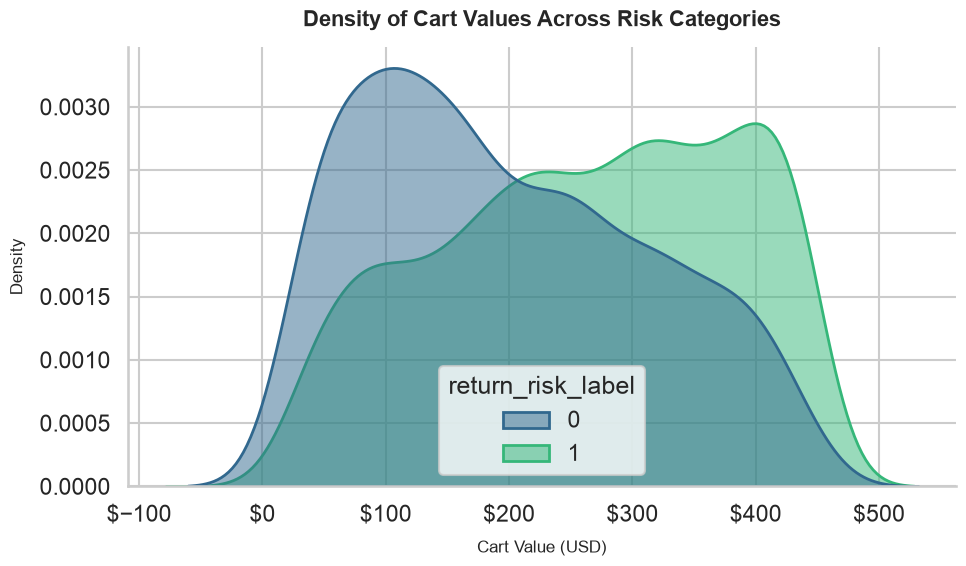

In [81]:
plt.figure(figsize=(10, 6))

ax2 = sns.kdeplot(
    data=df,
    x="cart_value_usd",
    hue="return_risk_label",
    fill=True,
    alpha=0.5,
    palette="viridis",
    linewidth=2,
    common_norm=False # Ensures each density curve integrates to 1 independently
)

plt.title("Density of Cart Values Across Risk Categories", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Cart Value (USD)", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Density", fontsize=12, fontweight="medium", labelpad=10)

ax2.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

sns.despine()
plt.tight_layout()
plt.show()


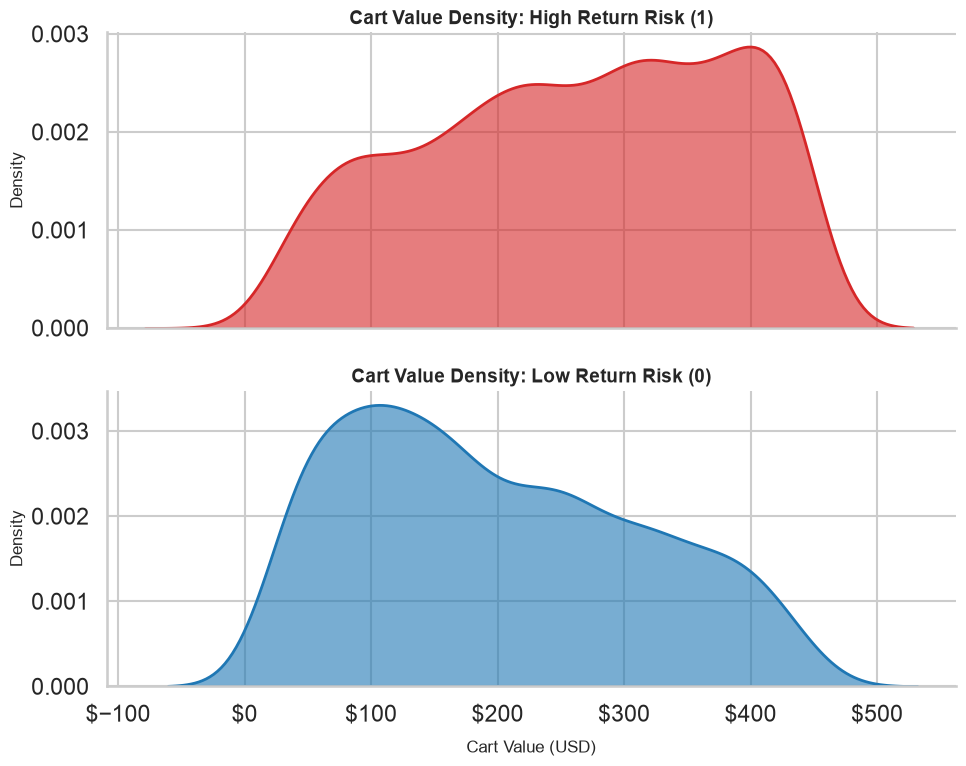

In [82]:
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 8), sharex=True)

# Top Plot: Risk = 1
sns.kdeplot(
    data=df[df["return_risk_label"] == 1],
    x="cart_value_usd",
    fill=True,
    alpha=0.6,
    color="#d62728", # Red implies risk/action
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title("Cart Value Density: High Return Risk (1)", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Density", fontsize=12, fontweight="medium")

# Bottom Plot: Risk = 0
sns.kdeplot(
    data=df[df["return_risk_label"] == 0],
    x="cart_value_usd",
    fill=True,
    alpha=0.6,
    color="#1f77b4", # Blue implies normal/safe
    linewidth=2,
    ax=axes[1]
)
axes[1].set_title("Cart Value Density: Low Return Risk (0)", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Density", fontsize=12, fontweight="medium")
axes[1].set_xlabel("Cart Value (USD)", fontsize=12, fontweight="medium", labelpad=10)

axes[1].xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

sns.despine()
plt.tight_layout()
plt.show()

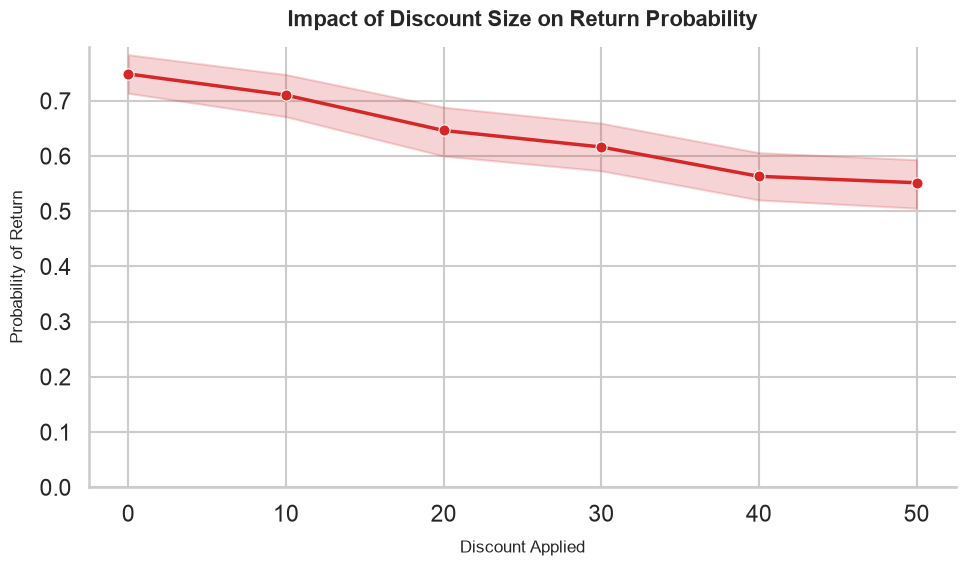

In [83]:
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(10, 6))

ax2 = sns.lineplot(
    data=df,
    x="discount_pct_applied",
    y="return_risk_label",
    color="#d62728",
    linewidth=2.5,
    marker="o",
    markersize=8,
    errorbar=("ci", 95)
)

plt.title("Impact of Discount Size on Return Probability", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Discount Applied", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Probability of Return", fontsize=12, fontweight="medium", labelpad=10)

plt.ylim(0, None)

sns.despine()
plt.tight_layout()
plt.show()

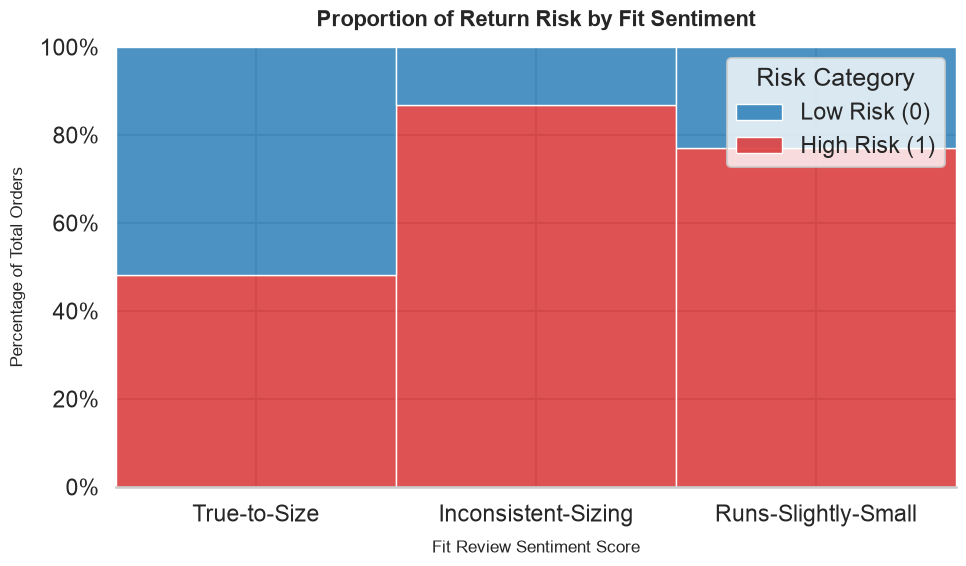

In [84]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(10, 6))

ax1 = sns.histplot(
    data=df,
    x="fit_review_sentiment",
    hue="return_risk_label",
    multiple="fill", 
    bins=15,
    palette=["#1f77b4", "#d62728"], # Blue = 0, Red = 1
    alpha=0.8,
    linewidth=1,
    edgecolor="white"
)

plt.title("Proportion of Return Risk by Fit Sentiment", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Fit Review Sentiment Score", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Percentage of Total Orders", fontsize=12, fontweight="medium", labelpad=10)

ax1.yaxis.set_major_formatter(PercentFormatter(1.0))

handles = ax1.get_legend().legend_handles
plt.legend(handles=handles, labels=["Low Risk (0)", "High Risk (1)"], title="Risk Category", loc="upper right", frameon=True)

sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

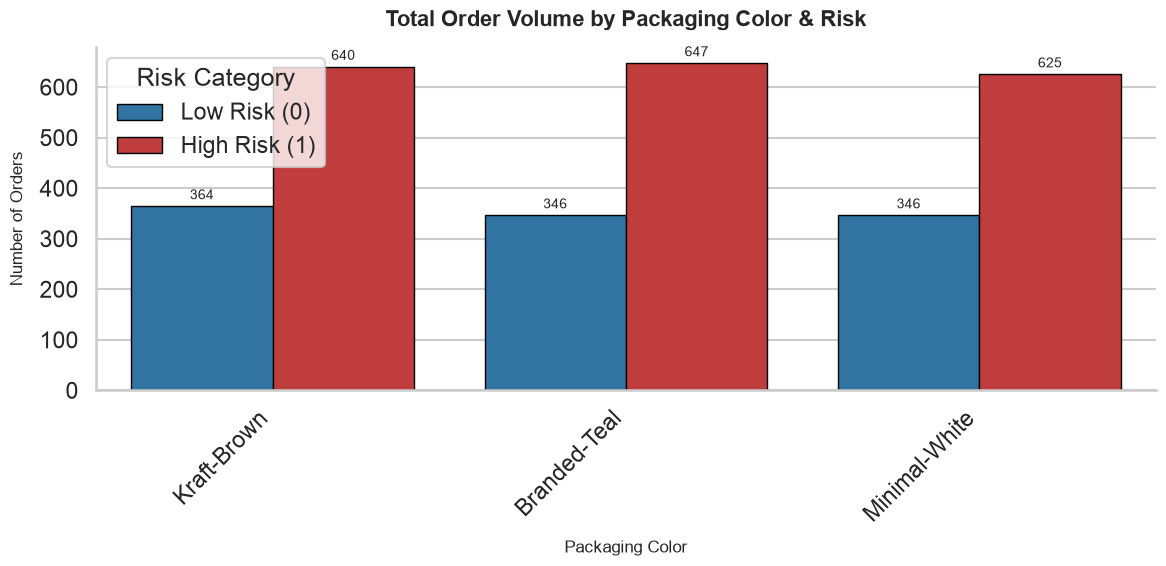

In [85]:
plt.figure(figsize=(12, 6))

# Sort by total volume (most popular packaging colors first)
volume_order = df['packaging_color'].value_counts().index

# Countplot shows raw volume split by the risk label
ax2 = sns.countplot(
    data=df,
    x="packaging_color",
    hue="return_risk_label",
    order=volume_order,
    palette=["#1f77b4", "#d62728"], # Blue = Safe, Red = Risk
    edgecolor="black",
    linewidth=1
)

plt.title("Total Order Volume by Packaging Color & Risk", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Packaging Color", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Number of Orders", fontsize=12, fontweight="medium", labelpad=10)

plt.xticks(rotation=45, ha="right")

# Clean up the legend
plt.legend(title="Risk Category", labels=["Low Risk (0)", "High Risk (1)"], frameon=True)

# Add data labels on top of the bars for exact counts
for container in ax2.containers:
    ax2.bar_label(container, fmt='%d', padding=3, fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_18725/3891159435.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


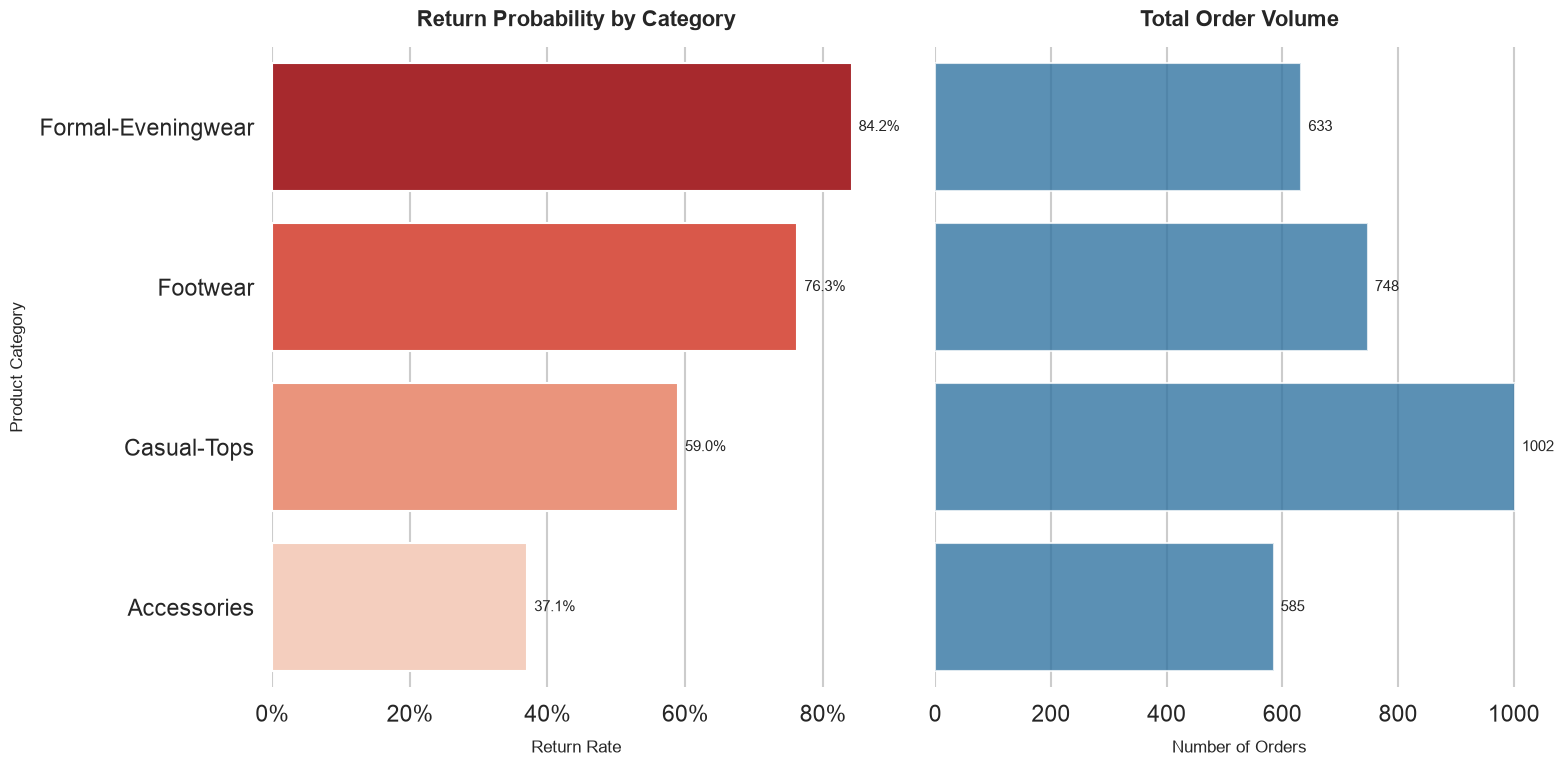

In [86]:
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 8), sharey=True)

category_order = df.groupby('product_category')['return_risk_label'].mean().sort_values(ascending=False).index

sns.barplot(
    data=df,
    y="product_category",
    x="return_risk_label",
    order=category_order,
    palette="Reds_r", 
    errorbar=None,    
    ax=axes[0]
)

axes[0].set_title("Return Probability by Category", fontsize=16, fontweight="bold", pad=15)
axes[0].set_xlabel("Return Rate", fontsize=12, fontweight="medium", labelpad=10)
axes[0].set_ylabel("Product Category", fontsize=12, fontweight="medium", labelpad=10)

axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
for container in axes[0].containers:
    axes[0].bar_label(container, fmt=lambda x: f'{x*100:.1f}%', padding=5, fontsize=11)

sns.countplot(
    data=df,
    y="product_category",
    order=category_order,
    color="#1f77b4", 
    alpha=0.8,
    ax=axes[1]
)

axes[1].set_title("Total Order Volume", fontsize=16, fontweight="bold", pad=15)
axes[1].set_xlabel("Number of Orders", fontsize=12, fontweight="medium", labelpad=10)
axes[1].set_ylabel("") 

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', padding=5, fontsize=11)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_18725/2439065764.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(
/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_18725/2439065764.py:49: UserWarning: Mismatched number of handles and labels: len(handles) = 4 len(labels) = 2
  axes[1].legend(handles=handles, labels=["Low Risk (0)", "High Risk (1)"], title="Risk Category", frameon=True)


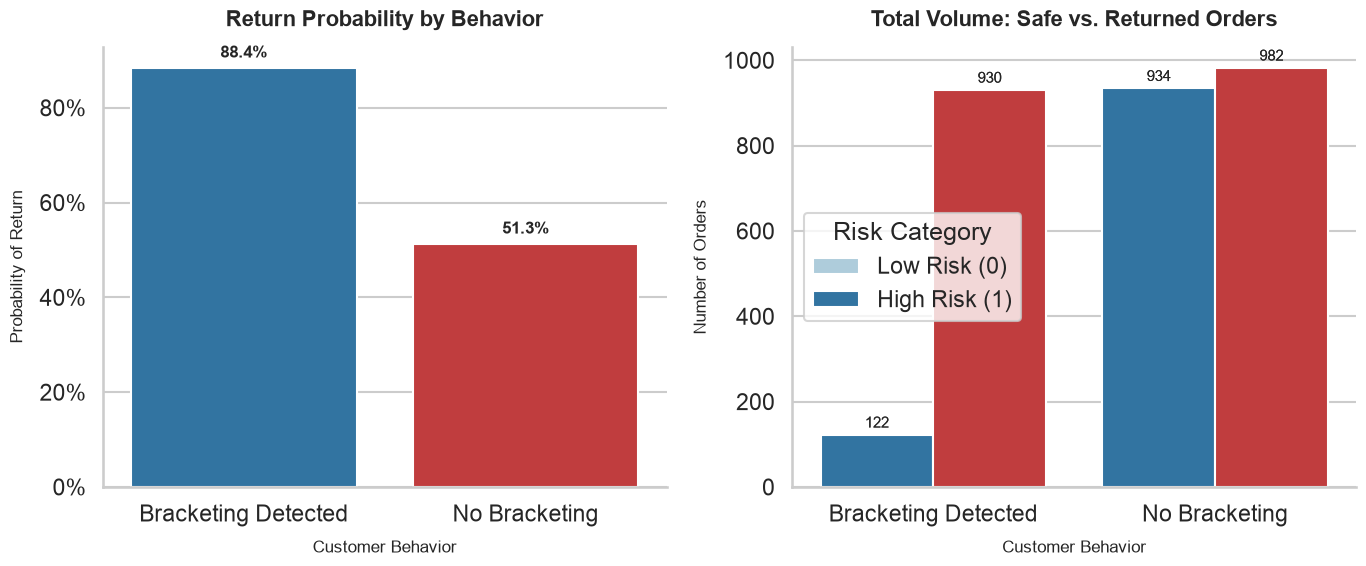

In [87]:
plot_df = df.copy()
plot_df['bracketing_text'] = plot_df['size_bracketing_flag'].map({0: 'No Bracketing', 1: 'Bracketing Detected'})

# Set professional theme
sns.set_theme(style="whitegrid", context="talk")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

ax1 = sns.barplot(
    data=plot_df,
    x="bracketing_text",
    y="return_risk_label",
    palette=["#1f77b4", "#d62728"], # Blue = Safe, Red = Danger
    errorbar=None, 
    ax=axes[0]
)

axes[0].set_title("Return Probability by Behavior", fontsize=16, fontweight="bold", pad=15)
axes[0].set_xlabel("Customer Behavior", fontsize=12, fontweight="medium", labelpad=10)
axes[0].set_ylabel("Probability of Return", fontsize=12, fontweight="medium", labelpad=10)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))

for container in axes[0].containers:
    axes[0].bar_label(container, fmt=lambda x: f'{x*100:.1f}%', padding=5, fontsize=12, fontweight='bold')

ax2 = sns.countplot(
    data=plot_df,
    x="bracketing_text",
    hue="return_risk_label",
    palette=["#a6cee3", "#1f78b4"], # Light blue vs Dark Blue for No Bracketing
    ax=axes[1]
)

sns.countplot(
    data=plot_df,
    x="bracketing_text",
    hue="return_risk_label",
    palette={0: "#1f77b4", 1: "#d62728"}, # Dictionary mapping guarantees 0 is Blue, 1 is Red
    ax=axes[1]
)

axes[1].set_title("Total Volume: Safe vs. Returned Orders", fontsize=16, fontweight="bold", pad=15)
axes[1].set_xlabel("Customer Behavior", fontsize=12, fontweight="medium", labelpad=10)
axes[1].set_ylabel("Number of Orders", fontsize=12, fontweight="medium", labelpad=10)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', padding=3, fontsize=11)

handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles=handles, labels=["Low Risk (0)", "High Risk (1)"], title="Risk Category", frameon=True)

sns.despine()
plt.tight_layout()
plt.show()

### Relationship Between Features and Target Variables

> 1. Cart Value and Past Return Rate don’t have any strong Relation
> 2. Delivery Days and Past Return Rate also Do not have any Strong Relations
> 3. But When Delivery days are long there is a high risk of return.
> 4.  When Cart Amount is High there is high Return Risk and when Low then returns are Low
> 5. When Discount is low there is high risk and it slightly down where there is discount
> 6. For Fit Sentiments if Inconsistent size this is more then 80% return risk,  when run slightly small then more then 70% of discount and when Ture to size then 50 percent
> 7. Packaging is not looks a relation with return
> 8.  For product Categories there is Very high Return Risk for Formal-Eveningwear that is 84%, for Footwear this is 76%, for Casual tops this is 59%, and for Accessories this is 37% 
> 9. When there is Bracketing is Detected this is High Chances of of 88% Order Returns


# Data Preprocessing

In [88]:
df.duplicated().sum()

np.int64(0)

In [89]:
df.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

### Creating X, and Y from data to train and test models.

In [90]:
X = df.drop(
    [
        "return_risk_label",
        "newsletter_subscriber",
        "browser_used",
        "checkout_device",
        "packaging_color",
    ],
    axis=1,
)
y = df['return_risk_label']
display(X)
display(y)

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,packaging_color,loyalty_card_color
0,172.17,0.233,1,11,10,Footwear,True-to-Size,Kraft-Brown,Platinum
1,213.55,0.235,1,6,40,Accessories,True-to-Size,Branded-Teal,Silver
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,Kraft-Brown,Gold
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,Kraft-Brown,Gold
4,152.68,0.133,0,3,40,Accessories,True-to-Size,Branded-Teal,Silver
...,...,...,...,...,...,...,...,...,...
2988,417.41,0.338,0,1,40,Casual-Tops,True-to-Size,Kraft-Brown,Silver
2989,81.61,0.153,1,7,0,Casual-Tops,True-to-Size,Kraft-Brown,Silver
2990,281.06,0.234,0,4,20,Casual-Tops,True-to-Size,Branded-Teal,Gold
2991,365.23,0.288,1,1,30,Formal-Eveningwear,True-to-Size,Branded-Teal,Silver


0       1
1       0
2       1
3       1
4       0
       ..
2988    0
2989    1
2990    0
2991    1
2992    1
Name: return_risk_label, Length: 2968, dtype: int64

In [91]:
print(all_cat_cols)

Index(['product_category', 'fit_review_sentiment', 'browser_used',
       'checkout_device', 'packaging_color', 'loyalty_card_color'],
      dtype='str')


In [92]:
categorical_cols = X.select_dtypes(include=["object", "str", "string"]).columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Features (X) head:")
display(X.head())
print("\nTarget (y) head:")
display(y.head())

Features (X) head:


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category_Casual-Tops,product_category_Footwear,product_category_Formal-Eveningwear,fit_review_sentiment_Runs-Slightly-Small,fit_review_sentiment_True-to-Size,packaging_color_Kraft-Brown,packaging_color_Minimal-White,loyalty_card_color_Platinum,loyalty_card_color_Silver
0,172.17,0.233,1,11,10,False,True,False,False,True,True,False,True,False
1,213.55,0.235,1,6,40,False,False,False,False,True,False,False,False,True
2,371.70,0.461,1,11,40,False,False,True,False,True,True,False,False,False
3,317.18,0.080,0,1,20,False,True,False,False,False,True,False,False,False
4,152.68,0.133,0,3,40,False,False,False,False,True,False,False,False,True



Target (y) head:


0    1
1    0
2    1
3    1
4    0
Name: return_risk_label, dtype: int64

In [93]:
from sklearn.model_selection import train_test_split

In [94]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (2374, 14)
X_test shape: (594, 14)
y_train shape: (2374,)
y_test shape: (594,)


In [95]:
from sklearn.preprocessing import StandardScaler

In [96]:
numerical_cols = X_train.select_dtypes(include=np.number).columns

scaler = StandardScaler()
X_train[numerical_cols] = X_train[numerical_cols].astype(float)
X_test[numerical_cols] = X_test[numerical_cols].astype(float)
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("X_train after scaling:")
display(X_train.head())
print("\nX_test after scaling:")
display(X_test.head())

X_train after scaling:


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category_Casual-Tops,product_category_Footwear,product_category_Formal-Eveningwear,fit_review_sentiment_Runs-Slightly-Small,fit_review_sentiment_True-to-Size,packaging_color_Kraft-Brown,packaging_color_Minimal-White,loyalty_card_color_Platinum,loyalty_card_color_Silver
1562,0.966893,0.830062,-0.729796,1.580951,1.509252,False,False,False,False,True,False,False,False,False
512,-1.277861,0.091312,-0.729796,1.270950,0.930515,False,False,False,False,False,False,True,True,False
1574,-1.361523,0.581633,1.370247,-0.279053,-0.226961,False,False,False,False,True,True,False,True,False
685,-0.702632,-0.006752,-0.729796,1.580951,0.351777,False,True,False,False,False,False,True,True,False
2886,0.731682,0.411655,-0.729796,1.270950,-0.805698,True,False,False,True,False,False,False,False,True



X_test after scaling:


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category_Casual-Tops,product_category_Footwear,product_category_Formal-Eveningwear,fit_review_sentiment_Runs-Slightly-Small,fit_review_sentiment_True-to-Size,packaging_color_Kraft-Brown,packaging_color_Minimal-White,loyalty_card_color_Platinum,loyalty_card_color_Silver
2418,-0.729639,-0.810879,-0.729796,0.030948,1.509252,True,False,False,True,False,False,True,False,False
1232,-0.925621,-0.529762,-0.729796,0.030948,-1.384436,False,False,False,False,False,False,True,False,False
2423,1.328714,-0.640901,-0.729796,0.340948,0.351777,True,False,False,True,False,False,True,False,True
335,0.155132,-0.307483,1.370247,-0.899054,-1.384436,False,True,False,True,False,False,False,True,False
1486,0.472436,-0.765116,1.370247,0.340948,0.930515,False,True,False,False,False,True,False,True,False


In [97]:
from imblearn.over_sampling import SMOTE

smt = SMOTE(random_state=42)
X_train_smote, y_train_smote = smt.fit_resample(X_train, y_train)

print("Original y_train distribution:")
display(y_train.value_counts())
print("\nResampled y_train_smote distribution:")
display(y_train_smote.value_counts())

Original y_train distribution:


return_risk_label
1    1514
0     860
Name: count, dtype: int64


Resampled y_train_smote distribution:


return_risk_label
0    1514
1    1514
Name: count, dtype: int64

In [98]:
from sklearn.linear_model import LogisticRegression

In [99]:
log_reg_model = LogisticRegression(random_state=42, solver='liblinear')
log_reg_model.fit(X_train_smote, y_train_smote)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1

In [100]:
y_pred_proba_log_reg = log_reg_model.predict_proba(X_test)[:, 1]

# Set threshold = 0.4
y_pred_log_reg = (y_pred_proba_log_reg >= 0.4).astype(int)

print("Predicted classes (first 5):")

display(y_pred_log_reg[:5])

print("\nPredicted probabilities (first 5):")

display(y_pred_proba_log_reg[:5])

Predicted classes (first 5):


array([0, 0, 1, 1, 1])


Predicted probabilities (first 5):


array([0.01018287, 0.35398427, 0.85702225, 0.99991938, 0.99995417])

In [101]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [102]:
accuracy = accuracy_score(y_test, y_pred_log_reg)
precision = precision_score(y_test, y_pred_log_reg)
recall = recall_score(y_test, y_pred_log_reg)
f1 = f1_score(y_test, y_pred_log_reg)

print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))

Accuracy : 0.931
Precision: 0.957
Recall   : 0.94
F1 Score : 0.948


In [103]:
from sklearn.metrics import roc_auc_score, roc_curve

ROC-AUC: 0.9819633883704235


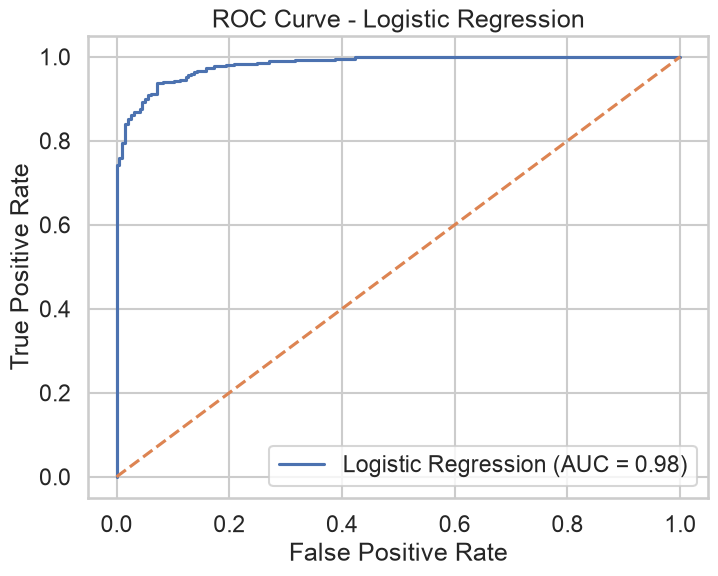

In [104]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_log_reg)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_pred_proba_log_reg)

print("ROC-AUC:", auc_score)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [105]:
from sklearn.metrics import confusion_matrix

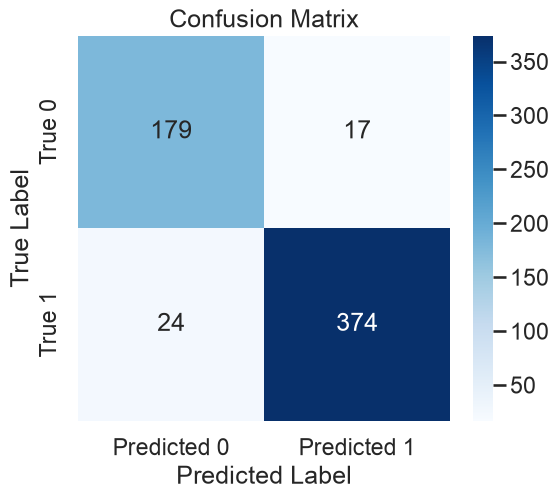

In [106]:
cm = confusion_matrix(y_test, y_pred_log_reg)
import seaborn as sns
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['True 0', 'True 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [107]:
from sklearn.naive_bayes import GaussianNB

In [108]:
nb_model = GaussianNB()
nb_model.fit(X_train_smote, y_train_smote)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1514.,1514.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,9.901e-10
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['cart_value_usd','past_return_rate','size_bracketing_flag',..., 'packaging_color_Minimal-White','loyalty_card_color_Platinum', 'loyalty_card_color_Silver']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 14)","[[-0.33,-0.25,-0.5 ,..., 0.36, 0.36, 0.38], [ 0.19, 0.14, 0.28,..., 0.32, 0.34, 0.34]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 14)","[[0.9 ,0.79,0.44,...,0.23,0.23,0.23], [0.95,1.03,1.1 ,...,0.22,0.22,0.22]]"


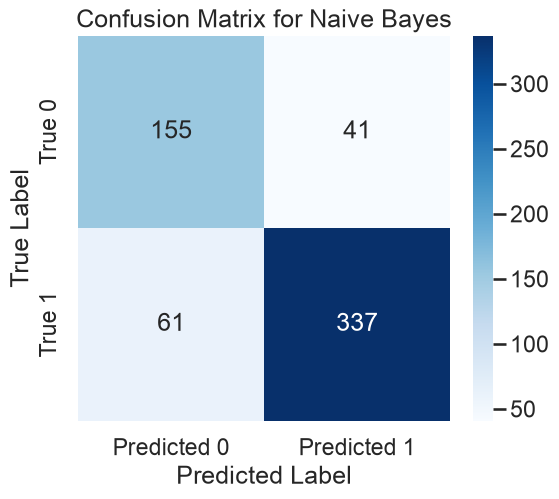

In [109]:
# Make predictions on the test set using the Naive Bayes model
y_pred_nb = nb_model.predict(X_test)
y_pred_proba_nb = nb_model.predict_proba(X_test)[:, 1]

# Calculate and display the Confusion Matrix for Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)


plt.figure(figsize=(6, 5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['True 0', 'True 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Naive Bayes')
plt.show()

In [110]:
from sklearn.metrics import classification_report

In [111]:
# Display the Classification Report for Naive Bayes
print("Classification Report for Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

Classification Report for Naive Bayes:
              precision    recall  f1-score   support

           0       0.72      0.79      0.75       196
           1       0.89      0.85      0.87       398

    accuracy                           0.83       594
   macro avg       0.80      0.82      0.81       594
weighted avg       0.83      0.83      0.83       594



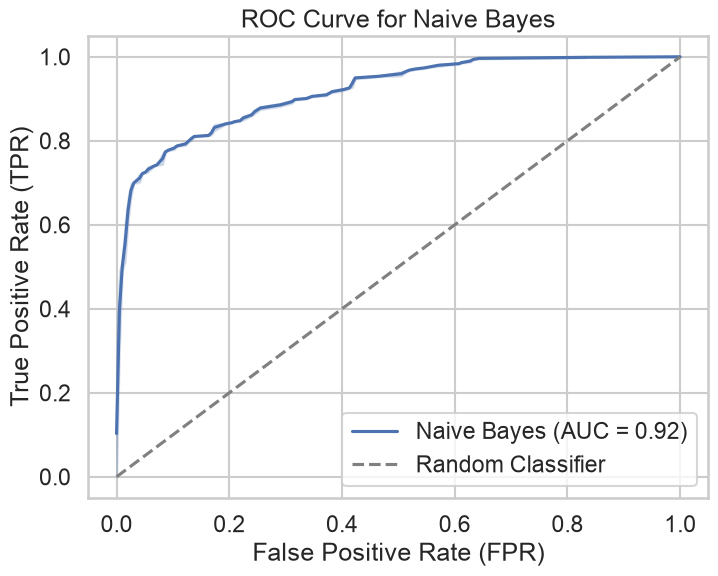

In [112]:
# Calculate ROC curve and AUC for Naive Bayes
fpr_nb, tpr_nb, thresholds_nb = roc_curve(y_test, y_pred_proba_nb)
roc_auc_nb = roc_auc_score(y_test, y_pred_proba_nb)

plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr_nb, y=tpr_nb, label=f'Naive Bayes (AUC = {roc_auc_nb:.2f})')
sns.lineplot(x=[0, 1], y=[0, 1], linestyle='--', color='gray', label='Random Classifier')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for Naive Bayes')
plt.legend()
plt.grid(True)
plt.show()

In [113]:
from sklearn.neighbors import KNeighborsClassifier

In [114]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_smote, y_train_smote)

# Make predictions on the test set using the KNN model
y_pred_knn = knn_model.predict(X_test)
y_pred_proba_knn = knn_model.predict_proba(X_test)[:, 1]



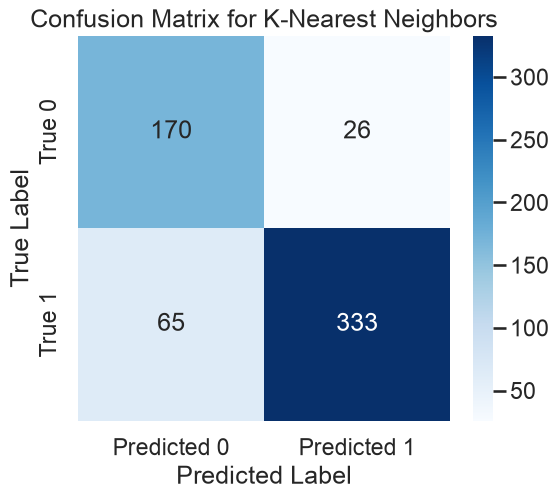

In [115]:
# Calculate and display the Confusion Matrix for KNN
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['True 0', 'True 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for K-Nearest Neighbors')
plt.show()

In [116]:
print('Classification Report for K-Nearest Neighbors:')
print(classification_report(y_test, y_pred_knn))

Classification Report for K-Nearest Neighbors:
              precision    recall  f1-score   support

           0       0.72      0.87      0.79       196
           1       0.93      0.84      0.88       398

    accuracy                           0.85       594
   macro avg       0.83      0.85      0.83       594
weighted avg       0.86      0.85      0.85       594



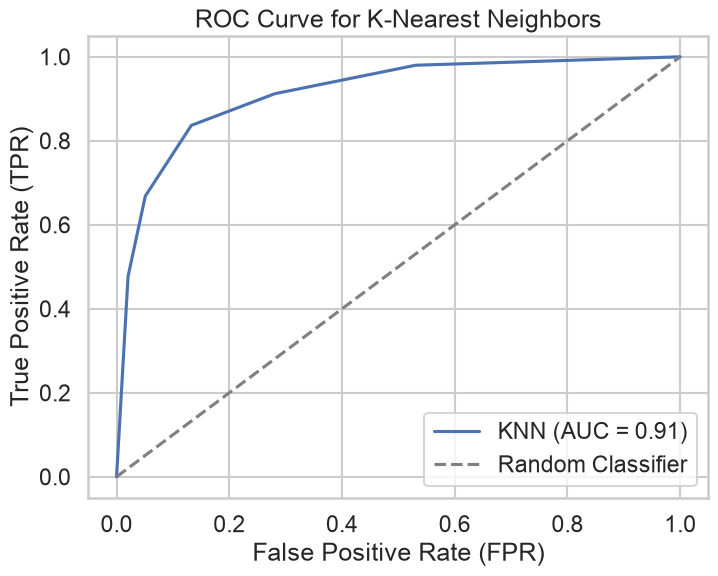

In [117]:
# Calculate ROC curve and AUC for KNN
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, y_pred_proba_knn)
roc_auc_knn = roc_auc_score(y_test, y_pred_proba_knn)

plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr_knn, y=tpr_knn, label=f'KNN (AUC = {roc_auc_knn:.2f})')
sns.lineplot(x=[0, 1], y=[0, 1], linestyle='--', color='gray', label='Random Classifier')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for K-Nearest Neighbors')
plt.legend()
plt.grid(True)
plt.show()

Comparison of All Models:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.931,0.957,0.940,0.948,0.982
1,K-Nearest Neighbors,0.847,0.928,0.837,0.880,0.914
2,Gaussian Naive Bayes,0.828,0.892,0.847,0.869,0.918


/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_18725/3930542989.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='F1 Score', y='Model', palette='viridis')


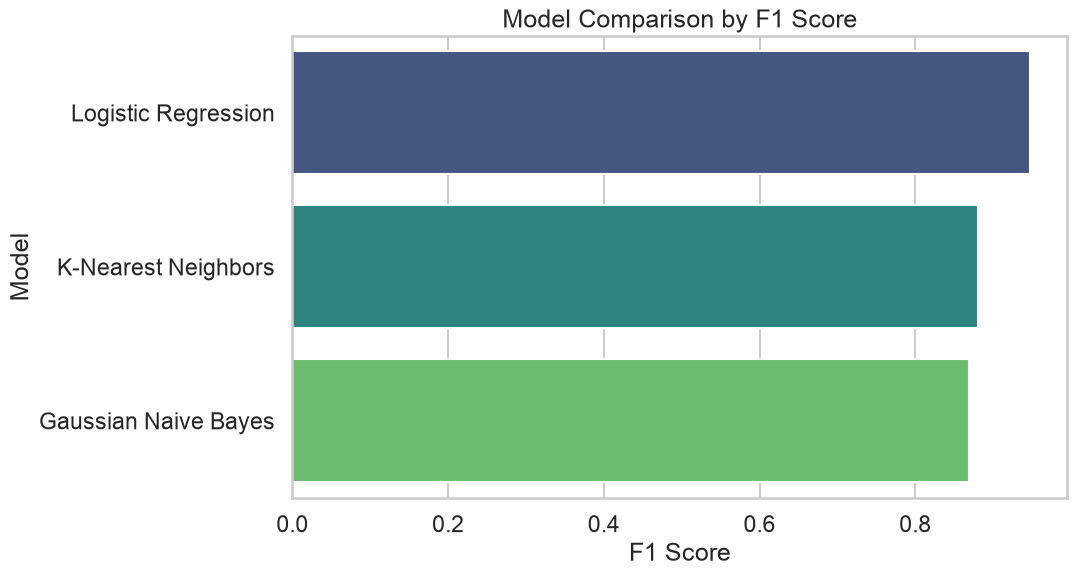

In [118]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_names = ['Logistic Regression', 'Gaussian Naive Bayes', 'K-Nearest Neighbors']
metrics = []

metrics.append({
    'Model': 'Logistic Regression',
    'Accuracy': round(accuracy_score(y_test, y_pred_log_reg), 3),
    'Precision': round(precision_score(y_test, y_pred_log_reg), 3),
    'Recall': round(recall_score(y_test, y_pred_log_reg), 3),
    'F1 Score': round(f1_score(y_test, y_pred_log_reg), 3),
    'ROC-AUC': round(roc_auc_score(y_test, y_pred_proba_log_reg), 3)
})

metrics.append({
    'Model': 'Gaussian Naive Bayes',
    'Accuracy': round(accuracy_score(y_test, y_pred_nb), 3),
    'Precision': round(precision_score(y_test, y_pred_nb), 3),
    'Recall': round(recall_score(y_test, y_pred_nb), 3),
    'F1 Score': round(f1_score(y_test, y_pred_nb), 3),
    'ROC-AUC': round(roc_auc_score(y_test, y_pred_proba_nb), 3)
})

metrics.append({
    'Model': 'K-Nearest Neighbors',
    'Accuracy': round(accuracy_score(y_test, y_pred_knn), 3),
    'Precision': round(precision_score(y_test, y_pred_knn), 3),
    'Recall': round(recall_score(y_test, y_pred_knn), 3),
    'F1 Score': round(f1_score(y_test, y_pred_knn), 3),
    'ROC-AUC': round(roc_auc_score(y_test, y_pred_proba_knn), 3)
})

comparison_df = pd.DataFrame(metrics).sort_values(by='F1 Score', ascending=False).reset_index(drop=True)
print('Comparison of All Models:')
display(comparison_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x='F1 Score', y='Model', palette='viridis')
plt.title('Model Comparison by F1 Score')
plt.xlabel('F1 Score')
plt.ylabel('Model')
plt.show()


/Volumes/Coding Work Place/Machine Learning/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Volumes/Coding Work Place/Machine Learning/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Volumes/Coding Work Place/Machine Learning/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set

Best Logistic Regression parameters: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best Logistic Regression CV F1-score: 0.9238
Best GaussianNB parameters: {'var_smoothing': 1e-09}
Best GaussianNB CV F1-score: 0.8181
Best KNN parameters: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Best KNN CV F1-score: 0.8803
Tuned model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.923,0.973,0.910,0.940,0.983
1,K-Nearest Neighbors,0.847,0.918,0.847,0.881,0.908
2,Gaussian Naive Bayes,0.828,0.892,0.847,0.869,0.918


/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_18725/1277352366.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='F1 Score', y='Model', palette='viridis')


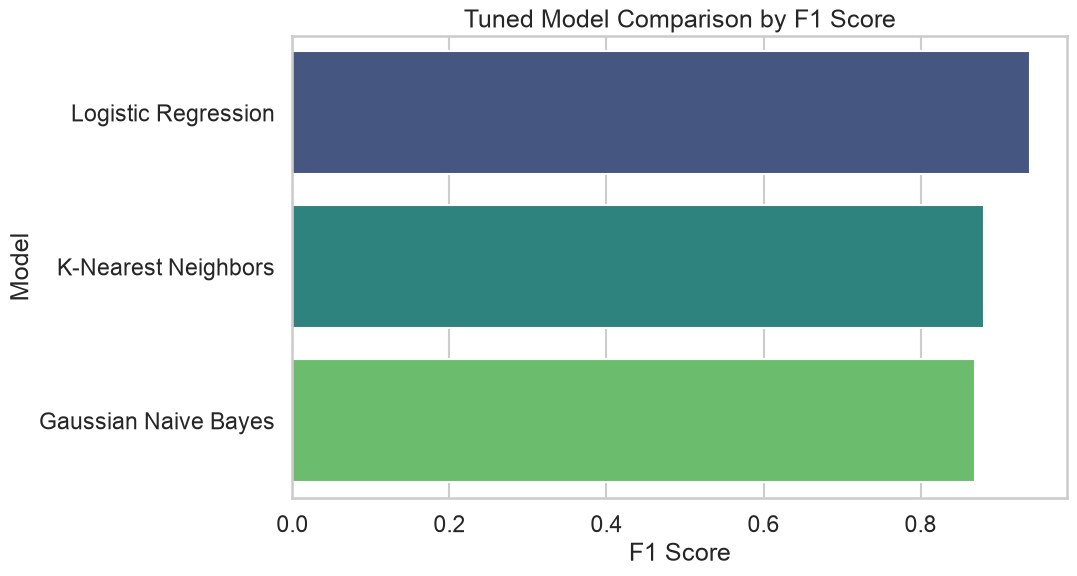

In [119]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter tuning with GridSearchCV
# We tune the models that have meaningful hyperparameters and compare them using F1-score.

logreg_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

logreg_grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=2000),
    param_grid=logreg_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
logreg_grid.fit(X_train_smote, y_train_smote)

print('Best Logistic Regression parameters:', logreg_grid.best_params_)
print('Best Logistic Regression CV F1-score:', round(logreg_grid.best_score_, 4))

best_logreg = logreg_grid.best_estimator_
y_pred_logreg_tuned = best_logreg.predict(X_test)
y_pred_proba_logreg_tuned = best_logreg.predict_proba(X_test)[:, 1]

nb_param_grid = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]
}

nb_grid = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=nb_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
nb_grid.fit(X_train_smote, y_train_smote)

print('Best GaussianNB parameters:', nb_grid.best_params_)
print('Best GaussianNB CV F1-score:', round(nb_grid.best_score_, 4))

best_nb = nb_grid.best_estimator_
y_pred_nb_tuned = best_nb.predict(X_test)
y_pred_proba_nb_tuned = best_nb.predict_proba(X_test)[:, 1]

knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
knn_grid.fit(X_train_smote, y_train_smote)

print('Best KNN parameters:', knn_grid.best_params_)
print('Best KNN CV F1-score:', round(knn_grid.best_score_, 4))

best_knn = knn_grid.best_estimator_
y_pred_knn_tuned = best_knn.predict(X_test)
y_pred_proba_knn_tuned = best_knn.predict_proba(X_test)[:, 1]

# Compare tuned models using key metrics
model_results = []
for name, model, y_pred, y_proba in [
    ('Logistic Regression', best_logreg, y_pred_logreg_tuned, y_pred_proba_logreg_tuned),
    ('Gaussian Naive Bayes', best_nb, y_pred_nb_tuned, y_pred_proba_nb_tuned),
    ('K-Nearest Neighbors', best_knn, y_pred_knn_tuned, y_pred_proba_knn_tuned)
]:
    model_results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 3),
        'Precision': round(precision_score(y_test, y_pred), 3),
        'Recall': round(recall_score(y_test, y_pred), 3),
        'F1 Score': round(f1_score(y_test, y_pred), 3),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 3)
    })

comparison_df = pd.DataFrame(model_results).sort_values(by='F1 Score', ascending=False).reset_index(drop=True)
print('Tuned model comparison:')
display(comparison_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x='F1 Score', y='Model', palette='viridis')
plt.title('Tuned Model Comparison by F1 Score')
plt.xlabel('F1 Score')
plt.ylabel('Model')
plt.show()


## Selecting Model
> As per upper Conclusion in my case Logistic is Performing very Well in Comparision with Other Models So Logistic will be perfect and Best model for my dataset

In [120]:
import pickle

with open("../models/classification_model.pkl", "wb") as f:
    pickle.dump(logreg_grid, f)


In [121]:
with open("../models/classification_model.pkl", "rb") as f:
    model = pickle.load(f)

In [122]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred))

Test accuracy: 0.923

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89       196
           1       0.97      0.91      0.94       398

    accuracy                           0.92       594
   macro avg       0.91      0.93      0.92       594
weighted avg       0.93      0.92      0.92       594

Confusion matrix (rows = actual, columns = predicted):
[[186  10]
 [ 36 362]]
